# Repeat Purchase Prediction, part 3
# Modelling

## Notebook purpose

This notebook starts from the cleaned data and the two pipelines built in `02_preprocessing.ipynb`. It tunes both, picks one, checks it once on the holdout and writes the Kaggle submission. It covers the modelling part of the homework. Other model families may be tried later for the final project, in a separate notebook.

## Approach

- **Same validation as before:** four expanding yearly folds (2020 to 2023) with a 90-day gap, and the holdout from 2024 left untouched until the final check.
- **Same decision rule:** F1 at each model's own threshold, a customer-level bootstrap of the F1 difference, and a fold-consistency check.
- **Tuning with Optuna.** A search can be steered either by log-loss or by F1, and every trial records both, so the two ways of steering can be compared.
- **Shared code lives in `src/`:** the cleaning and the pipelines in `repeat_purchase_prep.py`, the scoring and the decision rule in `evaluation.py`.

## Planned structure

1. **Setup and data**
2. **Starting point:** the two untuned pipelines
3. **Tuning setup**
4. **Logistic regression**
5. **Gradient boosting**
6. **Threshold and model choice**
7. **Holdout assessment**
8. **Final model and submission**
9. **Summary**

# 1. Setup and data

In [1]:
# Handle file paths without relying on computer-specific locations.
from pathlib import Path

# Locate the project from the current folder or one of its parent folders.
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

# Give a clear error if the expected project structure cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                  # original files, never modified
PROCESSED_DIR = DATA_DIR / "preprocessed"   # outputs of 02_preprocessing
SUBMISSION_DIR = DATA_DIR / "submissions"   # Kaggle files written by this notebook
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# The files this notebook needs from earlier steps
NEEDED = [
    PROCESSED_DIR / "train_clean.parquet",
    PROCESSED_DIR / "test_clean.parquet",
    PROCESSED_DIR / "decision_log.json",
    PROCESSED_DIR / "column_roles.json",
    RAW_DIR / "sample_submission.csv",
]
for path in NEEDED:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}. Run 02_preprocessing.ipynb first.")
print("All input files found.")

All input files found.


## 1.1. Imports and display settings

In [2]:
# Standard library
import sys
import json
import warnings

# Data and numbers
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook display
from IPython.display import display

# Hyperparameter search
import optuna
from optuna.visualization import (
    plot_optimization_history, plot_param_importances, plot_slice,
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.exceptions import ConvergenceWarning

# Metrics
from sklearn.metrics import f1_score, log_loss, roc_auc_score, confusion_matrix

# Project code in <project>/src
sys.path.insert(0, str(PROJECT_ROOT))
import src.repeat_purchase_prep as rpp
import src.evaluation as ev
import src.tuning as tn
from src.decision_log import DecisionLog

# Constants shared with 02_preprocessing
RANDOM_STATE = rpp.RANDOM_STATE
target = rpp.TARGET

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot style
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Optuna prints one line per trial by default; keep only warnings
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1.2. Data, folds and decision log

The cleaned files already contain every stateless repair from `02_preprocessing.ipynb`, so nothing is cleaned again here. The development set, the holdout and the four folds are rebuilt with the same functions, and the column roles are checked against the ones saved there, so both notebooks work on exactly the same inputs.

The decision log is loaded and continued, so every modelling choice ends up in the same record as the preprocessing ones.

In [3]:
train = pd.read_parquet(PROCESSED_DIR / "train_clean.parquet")
test = pd.read_parquet(PROCESSED_DIR / "test_clean.parquet")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

# Same splits and folds as in 02_preprocessing
dev, holdout = rpp.split_dev_holdout(train)
folds = rpp.year_folds(dev["purchase_date"])

# Same column roles as the ones saved by 02_preprocessing
roles = rpp.column_roles(dev)
saved_roles = json.loads((PROCESSED_DIR / "column_roles.json").read_text(encoding="utf-8"))
assert roles == saved_roles, "Column roles differ from 02_preprocessing"

# Continue the decision log from where preprocessing stopped
log = DecisionLog.load(PROCESSED_DIR / "decision_log.json")

print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Development: {len(dev):,} rows | Holdout: {len(holdout):,} rows | Folds: {len(folds)}")
print(f"Decisions logged so far: {len(log)} (last: {log.items[-1].step})")

Train: (6469, 53) | Test: (986, 52)
Development: 5,403 rows | Holdout: 835 rows | Folds: 4
Decisions logged so far: 32 (last: D30)


# 2. Starting point

The two pipelines from `02_preprocessing.ipynb` are scored with their default settings, so every tuned version below has something to be compared with. Training log-loss is reported next to validation log-loss: a model that does much better on the rows it learned from than on later rows is overfitting.

In [4]:
start_pipes = {
    "logistic": (
        rpp.build_linear_pipeline(LogisticRegression(max_iter=5000), roles),
        rpp.pipeline_inputs(roles, "linear"),
    ),
    "hist_gb": (
        rpp.build_tree_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), roles),
        rpp.pipeline_inputs(roles, "tree"),
    ),
}

start_runs = {}
for name, (pipe, inputs) in start_pipes.items():
    start_runs[name] = ev.score_folds(pipe, dev, folds, inputs, train_scores=True)

start_summary = pd.DataFrame({name: ev.summary_row(*run) for name, run in start_runs.items()}).T
display(start_summary)

,n_features,f1_stacked,f1_floor,log_loss,roc_auc,threshold,train_log_loss,overfit_gap
logistic,20.000,0.750,0.709,0.561,0.784,0.340,0.552,0.009
hist_gb,38.000,0.732,0.709,0.607,0.760,0.315,0.259,0.348


Both pipelines reproduce the scores from `02_preprocessing.ipynb`: F1 0.750 for logistic regression and 0.732 for gradient boosting, against an all-positive floor of 0.709.

The training log-loss tells two different stories. Logistic regression does almost as well on later years as on the rows it learned from, with a gap of 0.009, so it is not overfitting and tuning can only refine it. Gradient boosting reaches 0.259 on its training rows but 0.607 on later years, a gap of 0.348. It has largely memorised the rows it was fitted on. That points to where tuning matters most: settings that make the trees more cautious, such as more rows per leaf, fewer leaves, a penalty on leaf values and a slower learning rate.

# 3. Tuning setup

Tuning tries many settings for each model and keeps the best. Three choices shape how that is done here.

- **Preprocessing is fitted once per fold.** Only the model's settings change between trials, so the fill values, encoders and scaling are the same for every trial. Fitting them once per fold and reusing the result saves most of the work, an idea taken from the week 5 notebook. For logistic regression there are two versions, with and without the log transform from section 5.4 of `02_preprocessing.ipynb`, since that one is a setting to tune.
- **Optuna chooses the settings.** Instead of trying every combination on a grid, it learns from earlier trials which regions look promising and spends more trials there.
- **The search can be steered by log-loss or by F1.** Log-loss is smooth and uses every prediction, while F1 is the competition metric but jumps when a few rows cross the threshold. Each model is searched both ways with the same seed, and every trial records both metrics, so the two ways of steering can be compared directly. Whichever steers, the final choice between the best trials is made with the usual decision rule on F1.

Before any search, a check: the cached matrices with the default settings must reproduce the starting point exactly.

In [5]:
# Linear branch: two caches, with and without log1p on the skewed columns
log_cols = rpp.skewed_columns(dev, roles["num"])
linear_inputs = rpp.pipeline_inputs(roles, "linear")
linear_cache = {
    use_log: tn.FoldCache(
        rpp.build_linear_pipeline(LogisticRegression(), roles, log1p_cols=log_cols if use_log else None)
        .named_steps["prep"],
        dev, folds, linear_inputs,
    )
    for use_log in (False, True)
}

# Tree branch: one cache; small categories come first in its matrix
tree_inputs = rpp.pipeline_inputs(roles, "tree")
tree_cache = tn.FoldCache(
    rpp.build_tree_pipeline(HistGradientBoostingClassifier(), roles).named_steps["prep"],
    dev, folds, tree_inputs,
)
n_tree_cats = len([c for c in roles["low"] if c not in rpp.COARSE_DROP])

print(f"log1p candidates: {len(log_cols)} columns")
print(f"Linear matrix: {linear_cache[False].folds[-1]['X_train'].shape[1]} columns before selection")
print(f"Tree matrix: {tree_cache.folds[-1]['X_train'].shape[1]} columns, first {n_tree_cats} categorical")

log1p candidates: 27 columns
Linear matrix: 75 columns before selection
Tree matrix: 38 columns, first 7 categorical


In [6]:
# Default settings on the cached matrices must give the same scores as section 2
default_linear = Pipeline([
    ("select", SelectFromModel(LogisticRegression(
        l1_ratio=0.5, solver="saga", C=rpp.ENET_C, max_iter=5000, random_state=RANDOM_STATE))),
    ("model", LogisticRegression(max_iter=5000)),
])
default_tree = HistGradientBoostingClassifier(
    categorical_features=list(range(n_tree_cats)), random_state=RANDOM_STATE,
)

cached_runs = {
    "logistic": tn.evaluate_cached(linear_cache[False], default_linear),
    "hist_gb": tn.evaluate_cached(tree_cache, default_tree),
}
check = pd.DataFrame({
    f"{name} ({source})": ev.summary_row(*run)
    for name in ("logistic", "hist_gb")
    for source, run in [("base", start_runs[name]), ("cached", cached_runs[name])]
}).T
display(check[["n_features", "f1_stacked", "log_loss", "roc_auc", "threshold", "overfit_gap"]])

,n_features,f1_stacked,log_loss,roc_auc,threshold,overfit_gap
logistic (base),20.000,0.750,0.561,0.784,0.340,0.009
logistic (cached),20.000,0.750,0.561,0.784,0.340,0.009
hist_gb (base),38.000,0.732,0.607,0.760,0.315,0.348
hist_gb (cached),38.000,0.732,0.607,0.760,0.315,0.348


The cached matrices reproduce the starting point exactly, for both models, so the searches below run on the same inputs as every earlier comparison. The linear matrix has 75 columns before elastic net selects about 20 of them, and the tree matrix has 38, the first seven of them categorical.

# 4. Logistic regression

Four settings are tuned:

- **use_log:** whether the skewed columns are log-transformed first. It improved log-loss in section 5.4 of `02_preprocessing.ipynb` but not F1.
- **select_C:** how strongly elastic net selects columns. Smaller values keep fewer columns. Section 7.7 showed the F1 gain depended on it.
- **l1_ratio:** the mix in the selector, from close to ridge (0.1, keeps groups of related columns) to close to lasso (0.9, keeps one per group).
- **model_C:** the penalty on the final logistic regression. Smaller values pull the coefficients towards zero.

The search runs twice with the same seed and 60 trials each: once steered by log-loss and once by F1.

The choice is fixed before looking at the results. The five best trials of each search are compared with the untuned pipeline using the usual rule. If none is clearly better, the untuned pipeline stays. If several are, they are compared with the best of them in the same way, and among those not clearly worse the one with the fewest columns is chosen.

In [7]:
# saga can stop a little short of full convergence at some settings; the fold scores show the effect anyway
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def suggest_linear(trial):
    """Settings tried for the linear branch."""
    return {
        "use_log": trial.suggest_categorical("use_log", [False, True]),
        "select_C": trial.suggest_float("select_C", 0.03, 0.5, log=True),
        "l1_ratio": trial.suggest_float("l1_ratio", 0.1, 0.9),
        "model_C": trial.suggest_float("model_C", 1e-3, 100, log=True),
    }


def get_linear_cache(params):
    return linear_cache[bool(params["use_log"])]


def make_linear(params):
    """Elastic-net selection, then logistic regression, on the cached linear matrix."""
    return Pipeline([
        ("select", SelectFromModel(LogisticRegression(
            l1_ratio=params["l1_ratio"], solver="saga", C=params["select_C"],
            max_iter=5000, random_state=RANDOM_STATE,
        ))),
        ("model", LogisticRegression(C=params["model_C"], max_iter=5000)),
    ])

In [8]:
study_lin = {
    "log_loss": tn.tune(get_linear_cache, make_linear, suggest_linear,
                        objective="log_loss", n_trials=60, name="logistic_log_loss"),
    "f1": tn.tune(get_linear_cache, make_linear, suggest_linear,
                  objective="f1", n_trials=60, name="logistic_f1"),
}

# Five best trials of each search, with every recorded metric
show = ["use_log", "select_C", "l1_ratio", "model_C", "n_features",
        "log_loss", "f1", "threshold", "roc_auc", "overfit_gap"]
for objective, study in study_lin.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show])

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]


Steered by log_loss


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap
trial,,,,,,,,,,
42,True,0.033,0.655,0.010,14.500,0.549,0.742,0.350,0.781,-0.002
45,True,0.033,0.637,0.010,14.500,0.549,0.742,0.350,0.781,-0.003
47,True,0.033,0.635,0.015,14.500,0.549,0.744,0.385,0.781,-0.001
23,True,0.041,0.688,0.012,15.000,0.549,0.743,0.340,0.782,-0.001
33,True,0.040,0.860,0.012,13.750,0.549,0.742,0.360,0.781,-0.002



Steered by f1


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap
trial,,,,,,,,,,
41,False,0.058,0.102,0.096,23.500,0.560,0.753,0.335,0.783,0.007
51,False,0.035,0.105,0.053,23.750,0.560,0.753,0.325,0.783,0.006
28,False,0.046,0.143,0.026,23.750,0.559,0.753,0.330,0.782,0.003
49,False,0.036,0.108,0.080,23.750,0.561,0.752,0.325,0.783,0.007
34,False,0.064,0.158,0.127,23.500,0.560,0.752,0.340,0.783,0.008


The charts below show how each search progressed, which settings mattered most, and how log-loss and F1 relate across all trials.

In [9]:
for objective, study in study_lin.items():
    plot_optimization_history(study).update_layout(title=f"Logistic regression, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

# How log-loss moves with each setting (log-loss search)
plot_slice(study_lin["log_loss"]).update_layout(title="Log-loss against each setting").show()

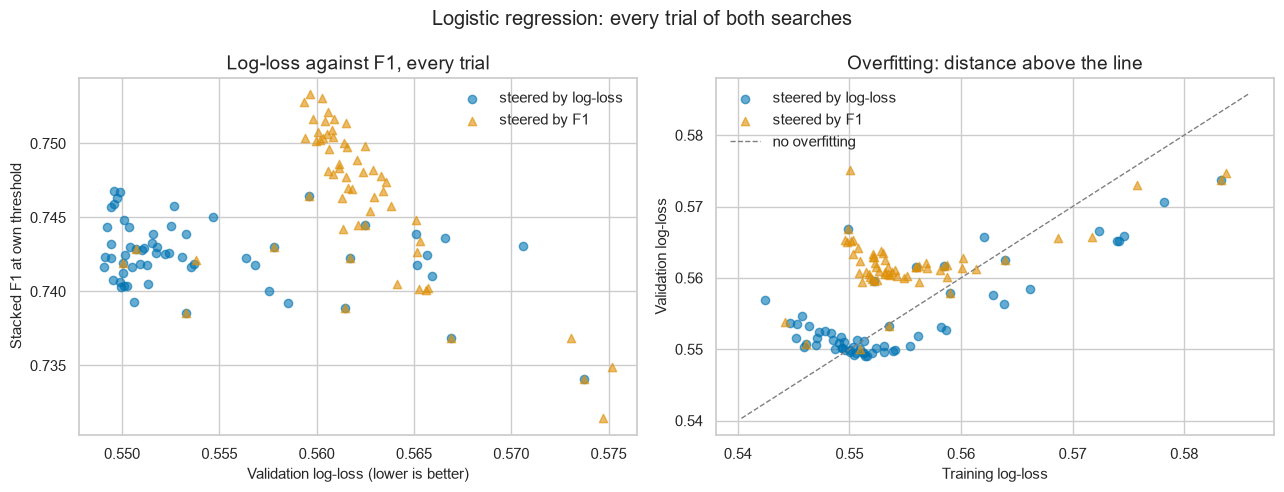

In [10]:
fig = tn.plot_trials(
    {"steered by log-loss": study_lin["log_loss"], "steered by F1": study_lin["f1"]},
    title="Logistic regression: every trial of both searches",
)
plt.show()

The five best trials of each search are re-scored and compared with the untuned pipeline using the decision rule.

In [11]:
# Top 5 of each search, named by search and trial number
candidates = {}
for objective, study in study_lin.items():
    candidates.update(tn.rescore(tn.top_params(study, 5), get_linear_cache, make_linear,
                                 prefix=f"{objective}_trial_"))

runs_lin = {"base": start_runs["logistic"], **candidates}
table_lin = ev.judge(runs_lin, "base")
display(table_lin)

# Among the clear winners: compare with the best of them, ties go to fewer columns
better = table_lin.index[table_lin["verdict"] == "better"].tolist()
if not better:
    chosen_tree = "base"
    print("No trial is clearly better than the untuned pipeline: base stays.")
else:
    best_name = table_lin.loc[better, "f1_stacked"].idxmax()
    table_better = ev.judge({name: runs_lin[name] for name in better}, best_name, tie_rule=True)
    display(table_better)
    equally_good = table_better.index[table_better["verdict"].isin(["reference", "tie, fewer columns", "no clear difference"])]
    # Fewest columns first; if those are equal, the best F1
    chosen_tree = (table_better.loc[equally_good]
                   .sort_values(["n_features", "f1_stacked"], ascending=[True, False])
                   .index[0])
    print(f"Chosen: {chosen_tree}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
log_loss_trial_42,14.500,0.742,-0.009,-0.020,0.002,3,0.350,0.549,0.140,0.781,no clear difference
log_loss_trial_45,14.500,0.742,-0.008,-0.019,0.003,3,0.350,0.549,0.140,0.781,no clear difference
log_loss_trial_47,14.500,0.744,-0.006,-0.018,0.005,2,0.385,0.549,0.140,0.781,no clear difference
log_loss_trial_23,15.000,0.743,-0.007,-0.018,0.004,3,0.340,0.549,0.139,0.782,no clear difference
log_loss_trial_33,13.750,0.742,-0.008,-0.020,0.003,3,0.360,0.549,0.139,0.781,no clear difference
f1_trial_41,23.500,0.753,0.003,-0.003,0.010,1,0.335,0.560,0.129,0.783,no clear difference
f1_trial_51,23.750,0.753,0.003,-0.004,0.012,2,0.325,0.560,0.129,0.783,no clear difference
f1_trial_28,23.750,0.753,0.002,-0.006,0.013,2,0.330,0.559,0.129,0.782,no clear difference


No trial is clearly better than the untuned pipeline: base stays.


Tuning does not clearly improve logistic regression on F1, so the untuned pipeline is kept.

Steered by log-loss, the search finds better probabilities. Log-loss drops from 0.561 to 0.549, and the best trials agree on the recipe: the log transform switched on and a strong penalty on the final model. Their F1 is between 0.742 and 0.744, slightly below the untuned 0.750, though not clearly so. The stronger penalty makes the probabilities more modest and better calibrated, while the ranking of customers gets a little blurrier, with ROC-AUC 0.781 to 0.782 against 0.784. It also brings training and validation log-loss together, closing the small gap seen in section 2.

Steered by F1, the best trials reach 0.752 to 0.753, up to 0.003 above the untuned pipeline. Every bootstrap interval includes zero, though, and a gap of this size is what picking the best of 60 noisy tries produces even when the settings make no real difference. Two further signs point to noise: the settings the F1 search rated as most important changed completely between a first run of 20 trials and the full run of 60, and 0.003 of F1 amounts to one or two test predictions changing side. The five best F1 trials do sit in the same region of settings, so a very small real gain cannot be ruled out, but the data cannot confirm it.

The two searches reward different things. Steered by log-loss, the penalty on the final model explains most of the variation, since it sets how confident the probabilities are. Steered by F1, the ranking near the threshold matters, and that surface is too noisy to point anywhere stable.

The better-calibrated version is not adopted, but it may still be useful later, for example if the probabilities of two models are averaged, where calibration matters more than the exact ranking.

In [12]:
log.record(
    "D31", "logistic regression settings", "keep the untuned pipeline (elastic net C = 0.1, model C = 1, no log1p)",
    "No tuned trial clearly better on F1 (60 trials per search). Log-loss steering improved log-loss "
    "(0.561 -> 0.549: log1p on, strong model penalty) but F1 fell to 0.742-0.744; F1 steering reached "
    "0.752-0.753 (+0.003, intervals include zero, consistent with best-of-60 optimism).",
    0, 0,
    carries={"chosen": "base", "best_log_loss_params": tn.top_params(study_lin["log_loss"], 1),
             "best_f1_params": tn.top_params(study_lin["f1"], 1)},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
32,D31,logistic regression settings,"keep the untuned pipeline (elastic net C = 0.1, model C = 1, no log1p)",No tuned trial clearly better on F1 (60 trials per search). Log-loss steering improved log-loss ...,0,0


# 5. Gradient boosting

Section 2 showed that gradient boosting with its default settings learns its training rows far better than later years, with a gap of 0.348 in log-loss. The settings tuned here all make the trees more cautious, in different ways:

- **learning_rate** and **max_iter:** how much each new tree corrects the previous ones, and how many trees there are. Smaller steps with more trees usually generalise better.
- **max_leaf_nodes:** how large each tree can grow. Smaller trees capture simpler patterns.
- **min_samples_leaf:** how many rows each leaf needs. Larger values stop the model from building rules for a handful of purchases.
- **l2_regularization:** a penalty that pulls extreme leaf values back towards zero.
- **max_features:** the share of columns each split may consider, which adds some randomness and makes the trees less alike.

Early stopping is left off, because it sets aside a random share of the training rows to decide when to stop, which would mix time periods inside a fold.

The search runs twice with the same seed and 60 trials each, once steered by log-loss and once by F1. The winner is chosen as for logistic regression: the five best trials of each search are compared with the untuned pipeline; if none is clearly better, the untuned pipeline stays; if several are, the one with the fewest columns among those not clearly worse than the best is chosen. Every trial here uses the same 38 columns, so in practice that tie goes to the trial with the best F1.

In [ ]:
def suggest_tree(trial):
    """Settings tried for the tree branch: all of them make the trees more or less cautious."""
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 800, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 300, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 30, log=True),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
    }

def get_tree_cache(params):
    return tree_cache  # the tree preprocessing has no tuned settings

def make_tree(params):
    """Gradient boosting on the cached tree matrix (small categories first)."""
    return HistGradientBoostingClassifier(
        **params,
        categorical_features=list(range(n_tree_cats)),
        early_stopping=False,  
        random_state=RANDOM_STATE,
    )

In [14]:
study_tree = {
    "log_loss": tn.tune(get_tree_cache, make_tree, suggest_tree,
                        objective="log_loss", n_trials=60, name="hist_gb_log_loss"),
    "f1": tn.tune(get_tree_cache, make_tree, suggest_tree,
                  objective="f1", n_trials=60, name="hist_gb_f1"),
}

show_tree = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf",
             "l2_regularization", "max_features", "log_loss", "f1", "threshold",
             "roc_auc", "train_log_loss", "overfit_gap"]
for objective, study in study_tree.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show_tree])

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]


Steered by log_loss


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap
trial,,,,,,,,,,,,
35,0.016,393,7,228,0.045,0.806,0.545,0.750,0.370,0.786,0.504,0.041
50,0.018,394,5,114,0.001,0.508,0.545,0.748,0.370,0.786,0.515,0.030
59,0.019,386,4,112,0.001,0.532,0.546,0.748,0.365,0.786,0.524,0.022
20,0.019,382,5,108,0.008,0.709,0.546,0.748,0.360,0.785,0.513,0.034
26,0.019,415,6,90,0.004,0.548,0.546,0.749,0.375,0.786,0.500,0.046



Steered by f1


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap
trial,,,,,,,,,,,,
32,0.025,52,17,29,0.013,0.324,0.570,0.755,0.450,0.787,0.540,0.030
52,0.015,67,14,23,0.008,0.355,0.584,0.754,0.460,0.785,0.563,0.021
59,0.026,65,23,32,0.004,0.372,0.559,0.754,0.420,0.787,0.506,0.053
17,0.018,57,25,29,0.003,0.497,0.579,0.753,0.455,0.782,0.538,0.041
44,0.026,59,23,30,0.006,0.412,0.563,0.753,0.425,0.784,0.513,0.050


The charts show how each search progressed, which settings mattered, and whether the tuned trees still overfit.

In [15]:
for objective, study in study_tree.items():
    plot_optimization_history(study).update_layout(title=f"Gradient boosting, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

plot_slice(study_tree["log_loss"]).update_layout(title="Log-loss against each setting").show()

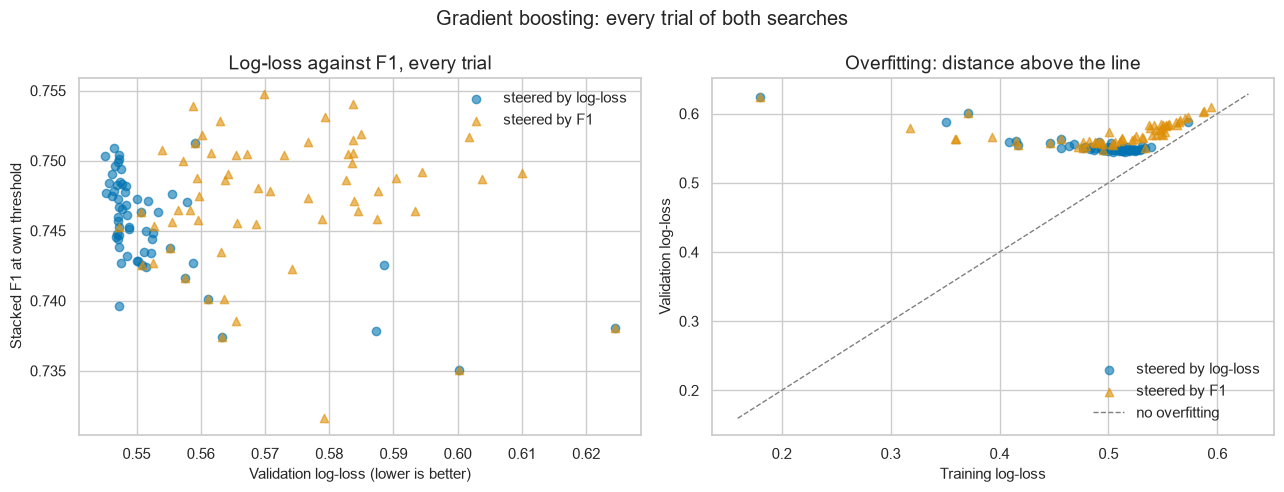

In [16]:
fig = tn.plot_trials(
    {"steered by log-loss": study_tree["log_loss"], "steered by F1": study_tree["f1"]},
    title="Gradient boosting: every trial of both searches",
)
plt.show()

The five best trials of each search are re-scored and compared with the untuned pipeline using the decision rule.

In [17]:
candidates = {}
for objective, study in study_tree.items():
    candidates.update(tn.rescore(tn.top_params(study, 5), get_tree_cache, make_tree,
                                 prefix=f"{objective}_trial_"))

runs_tree = {"base": start_runs["hist_gb"], **candidates}
table_tree = ev.judge(runs_tree, "base")
display(table_tree)

# Among the clear winners: compare with the best of them, ties go to fewer columns (equal here, so best F1)
better = table_tree.index[table_tree["verdict"] == "better"].tolist()
if not better:
    chosen_tree = "base"
    print("No trial is clearly better than the untuned pipeline: base stays.")
else:
    best_name = table_tree.loc[better, "f1_stacked"].idxmax()
    table_better = ev.judge({name: runs_tree[name] for name in better}, best_name, tie_rule=True)
    display(table_better)
    equally_good = table_better.index[table_better["verdict"].isin(["reference", "tie, fewer columns", "no clear difference"])]
    # Fewest columns first; if those are equal, the best F1
    chosen_tree = (table_better.loc[equally_good]
                   .sort_values(["n_features", "f1_stacked"], ascending=[True, False])
                   .index[0])
    print(f"Chosen: {chosen_tree}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,38.000,0.732,0.000,NaN,NaN,0,0.315,0.607,0.082,0.760,reference
log_loss_trial_35,38.000,0.750,0.019,0.006,0.033,0,0.370,0.545,0.144,0.786,better
log_loss_trial_50,38.000,0.748,0.016,0.003,0.031,0,0.370,0.545,0.144,0.786,better
log_loss_trial_59,38.000,0.748,0.017,0.003,0.032,0,0.365,0.546,0.143,0.786,better
log_loss_trial_20,38.000,0.748,0.016,0.003,0.031,0,0.360,0.546,0.143,0.785,better
log_loss_trial_26,38.000,0.749,0.018,0.006,0.032,0,0.375,0.546,0.143,0.786,better
f1_trial_32,38.000,0.755,0.023,0.009,0.039,0,0.450,0.570,0.119,0.787,better
f1_trial_52,38.000,0.754,0.023,0.008,0.040,0,0.460,0.584,0.105,0.785,better
f1_trial_59,38.000,0.754,0.022,0.009,0.038,0,0.420,0.559,0.130,0.787,better


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
log_loss_trial_35,38.000,0.750,-0.004,-0.013,0.003,3,0.370,0.545,0.144,0.786,no clear difference
log_loss_trial_50,38.000,0.748,-0.007,-0.016,0.002,3,0.370,0.545,0.144,0.786,no clear difference
log_loss_trial_59,38.000,0.748,-0.006,-0.017,0.003,3,0.365,0.546,0.143,0.786,no clear difference
log_loss_trial_20,38.000,0.748,-0.007,-0.017,0.002,3,0.360,0.546,0.143,0.785,no clear difference
log_loss_trial_26,38.000,0.749,-0.006,-0.014,0.002,4,0.375,0.546,0.143,0.786,no clear difference
f1_trial_32,38.000,0.755,0.000,NaN,NaN,0,0.450,0.570,0.119,0.787,reference
f1_trial_52,38.000,0.754,-0.001,-0.008,0.007,2,0.460,0.584,0.105,0.785,no clear difference
f1_trial_59,38.000,0.754,-0.001,-0.008,0.006,2,0.420,0.559,0.130,0.787,no clear difference
f1_trial_17,38.000,0.753,-0.002,-0.008,0.005,2,0.455,0.579,0.109,0.782,no clear difference


Chosen: f1_trial_32


Tuning clearly improves gradient boosting. All ten candidates beat the untuned pipeline: F1 rises by 0.016 to 0.023, every bootstrap interval stays above zero, and none is worse in any fold. Log-loss falls from 0.607 to as low as 0.545 and ROC-AUC rises from 0.760 to about 0.786. The gap between training and validation log-loss shrinks from 0.348 to between 0.02 and 0.05, so the tuned trees no longer memorise their training rows.

The two searches reach this in different ways. Steered by log-loss, they settle on many very small trees, about 390 of four to seven leaves with 90 to 230 rows per leaf, added with a slow learning rate. That gives smooth, well-calibrated probabilities. Steered by F1, they settle on few trees, around 50 to 70 with a similar learning rate, so the model stops early and its probabilities stay close to the base rate. That shows in a worse log-loss (0.56 to 0.58) and a higher threshold (about 0.45), while the ranking of customers is about as good.

Compared with the best of them, trial 32 of the F1 search, none of the other winners is clearly different. All use the same 38 columns, so by the rule set beforehand the best F1 decides and trial 32 is chosen, with F1 0.755. Being the best of 60 tries on F1, part of that score is likely selection luck, and the log-loss winners, which were not picked on F1, sit only slightly lower at about 0.750. The holdout will give an honest figure for the chosen model.

In [18]:
log.record(
    "D32", "gradient boosting settings", f"tuned settings from {chosen_tree}",
    "All ten top trials clearly better than the untuned pipeline (F1 +0.016 to +0.023, 0 folds worse; "
    "log-loss 0.607 -> 0.545-0.584; overfit gap 0.348 -> 0.02-0.05). No winner clearly different from "
    "the best; equal columns, so best F1 chosen (selection optimism likely).",
    0, 0,
    carries={"chosen": chosen_tree,
             "params": tn.top_params(study_tree["f1"], 1),
             "runner_up_log_loss_params": tn.top_params(study_tree["log_loss"], 1)},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
33,D32,gradient boosting settings,tuned settings from f1_trial_32,"All ten top trials clearly better than the untuned pipeline (F1 +0.016 to +0.023, 0 folds worse;...",0,0


# 6. Model choice and threshold

## 6.1. Choosing the model

Three candidates are compared on the same four folds: logistic regression with its untuned settings (section 4), gradient boosting with the tuned settings (section 5), and a blend that averages the two predicted probabilities half and half. Averaging two different kinds of model often helps when they make different mistakes, and a fixed half-and-half split adds nothing to tune.

The rule is fixed before looking. Logistic regression is the reference, being the simpler and more interpretable model, and gradient boosting replaces it only if it is clearly better on F1. The blend combines two models, so it is used only if it is clearly better than the single model chosen.

In [19]:
REFERENCE = "logistic"  # decided before the results

runs_choice = {
    "logistic": runs_lin["base"],
    "hist_gb_tuned": runs_tree[chosen_tree],
}
runs_choice["blend_50_50"] = ev.blend_runs(
    {"logistic": runs_choice["logistic"], "hist_gb_tuned": runs_choice["hist_gb_tuned"]}
)

other = "hist_gb_tuned" if REFERENCE == "logistic" else "logistic"
table_choice = ev.judge({REFERENCE: runs_choice[REFERENCE], other: runs_choice[other]}, REFERENCE)
display(table_choice)

# Step 1: the single model
single = other if table_choice.loc[other, "verdict"] == "better" else REFERENCE

# Step 2: the blend has to beat that single model clearly
table_blend = ev.judge({single: runs_choice[single], "blend_50_50": runs_choice["blend_50_50"]}, single)
display(table_blend)

chosen_model = "blend_50_50" if table_blend.loc["blend_50_50", "verdict"] == "better" else single
threshold = runs_choice[chosen_model][2]
print(f"Chosen model: {chosen_model} | threshold from the folds: {threshold:.3f}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
logistic,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
hist_gb_tuned,38.000,0.755,0.004,-0.007,0.017,1,0.450,0.570,0.119,0.787,no clear difference


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
logistic,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
blend_50_50,58.000,0.754,0.004,-0.003,0.011,2,0.400,0.551,0.138,0.790,no clear difference


Chosen model: logistic | threshold from the folds: 0.340


Logistic regression is kept. Tuned gradient boosting scores 0.004 higher in F1, with an interval from -0.007 to 0.017 and one fold worse, so the two cannot be told apart. The large gain from tuning in section 5 was over the untuned trees; against logistic regression the two models end up level.

The blend is not clearly better either: F1 is 0.004 higher, with an interval that includes zero. It does have the best log-loss (0.551) and ROC-AUC (0.790) of any candidate, so averaging the two models improves the probabilities, but not enough to move F1 beyond what chance could explain.

In [20]:
log.record(
    "D33", "final model", f"{chosen_model} (reference fixed beforehand: {REFERENCE})",
    "Tuned gradient boosting +0.004 F1 (CI -0.007 to 0.017) and the 50/50 blend +0.004 (CI -0.003 to 0.011) "
    "were not clearly better than logistic regression. The blend had the best log-loss (0.551) and ROC-AUC (0.790).",
    0, 0,
    carries={"chosen": chosen_model, "candidates": list(runs_choice)},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
34,D33,final model,logistic (reference fixed beforehand: logistic),Tuned gradient boosting +0.004 F1 (CI -0.007 to 0.017) and the 50/50 blend +0.004 (CI -0.003 to ...,0,0


## 6.2. Threshold and drift

The threshold comes from the four validation years stacked. It is fixed here and not changed afterwards. The share of repeat purchases moves from year to year, though, and is higher in the holdout (60.5%) than in development (55%). The chart shows the F1 curve for each validation year next to the stacked one: if the best threshold of each year sits close to the chosen one and the curves are flat around it, a shift in that share will cost little.

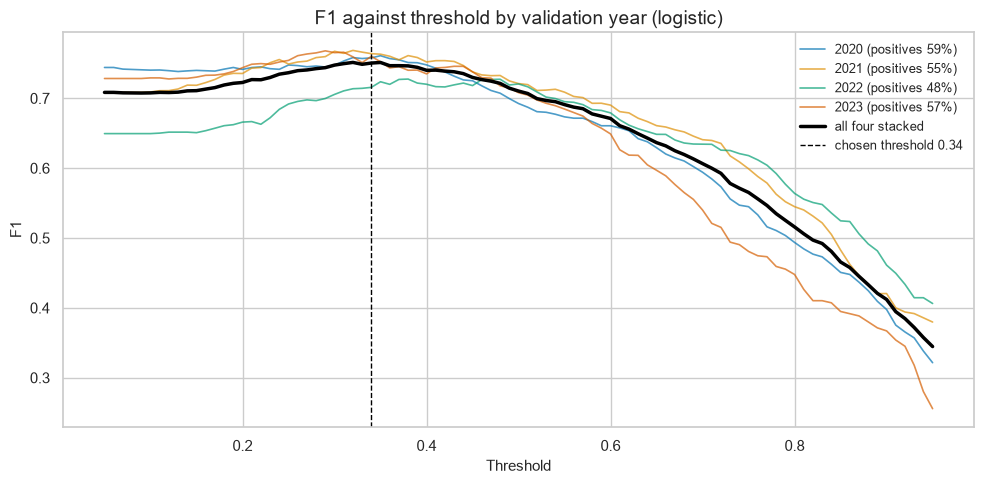

,positive_share,best_threshold,f1_at_best,f1_at_chosen,cost_of_fixed_threshold
fold,,,,,
2020,0.594,0.340,0.761,0.758,0.003
2021,0.549,0.320,0.769,0.764,0.005
2022,0.481,0.420,0.728,0.716,0.012
2023,0.573,0.290,0.768,0.760,0.008


In [21]:
oof_chosen = runs_choice[chosen_model][1]

fig, ax = plt.subplots(figsize=(10, 5))
rows = []
for year, part in oof_chosen.groupby("fold"):
    best_t, grid, f1s = rpp.best_threshold(part["y"], part["p"])
    ax.plot(grid, f1s, lw=1.2, alpha=0.7, label=f"{year} (positives {part['y'].mean():.0%})")
    rows.append({
        "fold": year, "positive_share": part["y"].mean(), "best_threshold": best_t,
        "f1_at_best": f1s.max(), "f1_at_chosen": f1_score(part["y"], part["p"] >= threshold),
    })

_, grid, f1s = rpp.best_threshold(oof_chosen["y"], oof_chosen["p"])
ax.plot(grid, f1s, color="black", lw=2.5, label="all four stacked")
ax.axvline(threshold, color="black", ls="--", lw=1, label=f"chosen threshold {threshold:.2f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("F1")
ax.set_title(f"F1 against threshold by validation year ({chosen_model})")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

threshold_table = pd.DataFrame(rows).set_index("fold")
threshold_table["cost_of_fixed_threshold"] = threshold_table["f1_at_best"] - threshold_table["f1_at_chosen"]
display(threshold_table)

The chosen threshold of 0.34 sits at the peak of the stacked curve, and the yearly curves are fairly flat around it. Fixing it costs between 0.003 and 0.012 F1 per year compared with each year's own best. The cost is largest in 2022, the year with the fewest repeat purchases (48%), where the best threshold is higher, at 0.42. So a moderate shift in the share of positives costs little F1, though not nothing.

# 7. Holdout assessment

The chosen model is fitted on the whole development set and scored once on the holdout, the purchases from 2024 to February 2025. The threshold is the one fixed above. Nothing is changed after seeing these numbers: their only purpose is an honest estimate of how the model does on a period that played no part in any choice.

Results are also split into customers already seen in development and new customers, since the model has history for the first group only.

In [22]:
# Settings of the chosen gradient boosting trial (empty if the untuned one had been kept)
if chosen_tree == "base":
    tree_params = {}
else:
    search, number = chosen_tree.rsplit("_trial_", 1)
    tree_params = dict(study_tree[search].trials[int(number)].params)


def fit_predict(model_name, fit_rows, predict_rows):
    """Fit the named model on fit_rows and return probabilities for predict_rows."""
    preds = {}
    if model_name in ("logistic", "blend_50_50"):
        lin = rpp.build_linear_pipeline(LogisticRegression(max_iter=5000), roles)
        lin.fit(fit_rows[linear_inputs], fit_rows[target])
        preds["logistic"] = lin.predict_proba(predict_rows[linear_inputs])[:, 1]
    if model_name in ("hist_gb_tuned", "blend_50_50"):
        tree = rpp.build_tree_pipeline(
            HistGradientBoostingClassifier(**tree_params, early_stopping=False, random_state=RANDOM_STATE), roles,
        )
        tree.fit(fit_rows[tree_inputs], fit_rows[target])
        preds["hist_gb_tuned"] = tree.predict_proba(predict_rows[tree_inputs])[:, 1]
    return np.mean(list(preds.values()), axis=0)  # one model: itself; blend: the half-and-half average

In [23]:
p_holdout = fit_predict(chosen_model, dev, holdout)
y_holdout = holdout[target].to_numpy()
pred_holdout = p_holdout >= threshold
seen = holdout["customer_id"].isin(dev["customer_id"]).to_numpy()

holdout_scores = pd.DataFrame({
    "all rows": {
        "rows": len(y_holdout),
        "positive_share": y_holdout.mean(),
        "f1": f1_score(y_holdout, pred_holdout),
        "f1_floor": rpp.f1_floor(y_holdout),
        "log_loss": log_loss(y_holdout, p_holdout),
        "roc_auc": roc_auc_score(y_holdout, p_holdout),
        "predicted_positive_share": pred_holdout.mean(),
    },
    **{
        group: {
            "rows": int(mask.sum()),
            "positive_share": y_holdout[mask].mean(),
            "f1": f1_score(y_holdout[mask], pred_holdout[mask]),
            "f1_floor": rpp.f1_floor(y_holdout[mask]),
        }
        for group, mask in [("seen customers", seen), ("new customers", ~seen)]
    },
}).T
holdout_scores["lift"] = holdout_scores["f1"] - holdout_scores["f1_floor"]
display(holdout_scores)

# Confusion matrix at the fixed threshold
cm = pd.DataFrame(confusion_matrix(y_holdout, pred_holdout),
                  index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"])
display(cm)

# For reading only: what the best threshold on the holdout would have been
best_holdout_t, _, best_f1s = rpp.best_threshold(y_holdout, p_holdout)
print(f"For reference only: best holdout threshold {best_holdout_t:.2f} "
      f"would give F1 {best_f1s.max():.3f} (not used)")

,rows,positive_share,f1,f1_floor,log_loss,roc_auc,predicted_positive_share,lift
all rows,835.000,0.605,0.781,0.754,0.560,0.784,0.732,0.028
seen customers,757.000,0.625,0.794,0.769,NaN,NaN,NaN,0.025
new customers,78.000,0.410,0.592,0.582,NaN,NaN,NaN,0.010


,predicted 0,predicted 1
actual 0,155,175
actual 1,69,436


For reference only: best holdout threshold 0.38 would give F1 0.789 (not used)


On the holdout, logistic regression reaches F1 0.781, above the all-positive floor of 0.754. Log-loss (0.560) and ROC-AUC (0.784) are almost exactly the values seen on the folds, so both the probabilities and the ranking of customers carry over to a new period without loss. The lift over the floor is smaller than on the folds, 0.028 against 0.041. The holdout has more repeat purchases (60.5%), which raises the floor and leaves less room above it.

At the fixed threshold the model predicts a repeat for 73% of purchases, against 60.5% that actually repeat. That is the expected behaviour under F1, which rewards catching repeats more than avoiding false alarms. Among new customers, F1 is only 0.010 above their floor, on 78 rows: without a purchase history the model has little to go on.

The best threshold on the holdout itself would have been 0.38, with F1 0.789. It is not used here, since choosing it on these rows would turn the holdout into one more round of tuning, and its score would no longer be an honest estimate.

In [24]:
log.record(
    "D34", "holdout assessment", f"{chosen_model} scored once at threshold {threshold:.2f}",
    f"F1 {holdout_scores.loc['all rows', 'f1']:.3f} vs floor {holdout_scores.loc['all rows', 'f1_floor']:.3f}; "
    f"log-loss {holdout_scores.loc['all rows', 'log_loss']:.3f}, ROC-AUC {holdout_scores.loc['all rows', 'roc_auc']:.3f} "
    "(in line with the folds). New customers: lift 0.010 on 78 rows. Holdout-best threshold 0.38 not used.",
    0, len(holdout),
    carries={"threshold": threshold, "holdout_f1": float(holdout_scores.loc["all rows", "f1"])},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
35,D34,holdout assessment,logistic scored once at threshold 0.34,"F1 0.781 vs floor 0.754; log-loss 0.560, ROC-AUC 0.784 (in line with the folds). New customers: ...",0,835


# 8. Final model and submission

## 8.1. Threshold for the submission

The holdout assessment is done, so its rows can now join the evidence, just as the final model is refitted on every labelled row. The holdout works exactly like a fifth yearly fold: a model trained on purchases before October 2023 and scored on 2024 to February 2025. Its predictions are added to the four folds, and the threshold is picked again with the same rule on all five years stacked. The most recent year gets a say, which matters when the share of repeat purchases keeps rising.

The holdout score above, at the threshold fixed beforehand, remains the honest estimate. This only decides the threshold used for the test set.

In [25]:
# Holdout predictions as a fifth fold, next to the four validation years
oof_five = pd.concat([
    oof_chosen[["fold", "y", "p"]],
    pd.DataFrame({"fold": 2024, "y": y_holdout, "p": p_holdout}),
], ignore_index=True)

threshold_final, grid, f1s_five = rpp.best_threshold(oof_five["y"], oof_five["p"])

print(f"Threshold on four folds: {threshold:.2f} | on five years: {threshold_final:.2f}")
print(f"Stacked F1 on five years at {threshold:.2f}: {f1_score(oof_five['y'], oof_five['p'] >= threshold):.3f} | "
      f"at {threshold_final:.2f}: {f1s_five.max():.3f}")

Threshold on four folds: 0.34 | on five years: 0.35
Stacked F1 on five years at 0.34: 0.759 | at 0.35: 0.760


In [26]:
log.record(
    "D35", "decision threshold", f"{threshold_final:.2f} for the submission (picked on five years stacked)",
    f"Same rule as before on four folds plus the holdout as a fifth year; four-fold threshold was {threshold:.2f}. "
    "The holdout score at the fixed threshold stays the honest estimate.",
    0, 0,
    carries={"threshold_final": threshold_final, "threshold_four_folds": threshold},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
36,D35,decision threshold,0.35 for the submission (picked on five years stacked),Same rule as before on four folds plus the holdout as a fifth year; four-fold threshold was 0.34...,0,0


## 8.2. Final fit and test predictions

The chosen model is refitted on all 6,469 labelled purchases, development, gap and holdout together, so the most recent data shapes it. The test predictions then go through a few checks before the file is written: the right number of rows, the same IDs in the same order as the sample submission, only 0 and 1 as values, and a share of predicted repeats in line with the holdout.

One further check looks at the 41 test rows whose customers started after 2024, the case section 6.2 of `02_preprocessing.ipynb` flagged for linear models. Their predicted probabilities should not stand far apart from the rest.

In [27]:
p_test = fit_predict(chosen_model, train, test)
pred_test = (p_test >= threshold_final).astype(int)

# Same layout as the sample submission
id_col, target_col = sample_submission.columns[:2]
submission = sample_submission[[id_col]].merge(
    pd.DataFrame({id_col: test[id_col].to_numpy(), target_col: pred_test}),
    on=id_col, how="left", validate="one_to_one",
)

# Checks 
assert len(submission) == len(sample_submission) == len(test), "Row count differs"
assert submission[id_col].equals(sample_submission[id_col]), "IDs are not in the sample order"
assert submission[target_col].notna().all(), "Some IDs got no prediction"
assert set(submission[target_col].unique()) <= {0, 1}, "Values other than 0 and 1"

print(f"Rows: {len(submission)} | predicted repeat share: {submission[target_col].mean():.1%} "
      f"(holdout: {pred_holdout.mean():.1%})")
print(f"Mean probability, test: {p_test.mean():.3f} | holdout: {p_holdout.mean():.3f}")

# Customers who started after the last start year in training
late_start = (test["customer_since_year"] > train["customer_since_year"].max()).to_numpy()
print(f"Late-start rows: {late_start.sum()} | mean probability {p_test[late_start].mean():.3f} "
      f"vs {p_test[~late_start].mean():.3f} for the rest")

Rows: 986 | predicted repeat share: 80.2% (holdout: 73.2%)
Mean probability, test: 0.599 | holdout: 0.551
Late-start rows: 41 | mean probability 0.282 vs 0.613 for the rest


In [28]:
# Late-start rows: is the low probability "new customer" or "start year beyond training"?
p_test_tree = fit_predict("hist_gb_tuned", train, test)  # trees cap the start year at the last value seen
new_in_test = ~test["customer_id"].isin(train["customer_id"]).to_numpy()
new_holdout = ~seen

diag = pd.DataFrame({
    "rows": [late_start.sum(), (new_in_test & ~late_start).sum(), new_holdout.sum()],
    "logistic_mean_p": [p_test[late_start].mean(), p_test[new_in_test & ~late_start].mean(), p_holdout[new_holdout].mean()],
    "hist_gb_mean_p": [p_test_tree[late_start].mean(), p_test_tree[new_in_test & ~late_start].mean(), np.nan],
    "actual_repeat_share": [np.nan, np.nan, y_holdout[new_holdout].mean()],
}, index=["test: start after 2024", "test: new, start 2024 or earlier", "holdout: new customers"])
display(diag)

,rows,logistic_mean_p,hist_gb_mean_p,actual_repeat_share
test: start after 2024,41,0.282,0.431,NaN
"test: new, start 2024 or earlier",13,0.353,0.569,NaN
holdout: new customers,78,0.389,NaN,0.410


The 41 test rows whose customers started after 2024 get a mean probability of 0.282, far below the rest. A comparison with gradient boosting shows that this is about the customers being new rather than about the start year lying beyond the training data. Gradient boosting cannot extend a trend past the last start year it saw, yet it also gives these rows lower probabilities than the other new customers (0.431 against 0.569). Logistic regression is lower than gradient boosting for every group of new customers, not just these, and on the holdout its probabilities for new customers matched what happened well (0.389 predicted, 0.410 observed). The submission is therefore kept as it is.

## 8.3. Saving the submission and the logs

The file name carries the model and the time it was made. A small submission log keeps one line per file with the scores behind it, and a column for the public leaderboard score, filled in by hand after uploading. The decision log is saved under its own name, so rerunning `02_preprocessing.ipynb` does not overwrite the modelling decisions.

In [29]:
stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M")
sub_path = SUBMISSION_DIR / f"submission_{chosen_model}_{stamp}.csv"
submission.to_csv(sub_path, index=False)

# One line per submission; public_score is filled in by hand after uploading
fold_f1 = f1_score(oof_chosen["y"], oof_chosen["p"] >= threshold)
sub_log_path = SUBMISSION_DIR / "submission_log.csv"
entry = pd.DataFrame([{
    "file": sub_path.name, "created": stamp, "model": chosen_model,
    "threshold": round(threshold_final, 3), "fold_f1": round(fold_f1, 4),
    "holdout_f1": round(float(holdout_scores.loc["all rows", "f1"]), 4),
    "predicted_repeat_share": round(float(submission[target_col].mean()), 4),
    "public_score": None, "notes": "",
}])
if sub_log_path.is_file():
    entry = pd.concat([pd.read_csv(sub_log_path), entry], ignore_index=True)
entry.to_csv(sub_log_path, index=False)

log.record(
    "D36", "submission", f"{sub_path.name}",
    f"{chosen_model} refitted on all {len(train):,} labelled rows, threshold {threshold_final:.2f}; "
    f"predicted repeat share {submission[target_col].mean():.1%}. Late-start rows (41) checked against "
    "gradient boosting: low probabilities reflect new customers, not start-year extrapolation.",
    0, len(test),
    carries={"file": sub_path.name, "model": chosen_model, "threshold": threshold_final},
)

log.to_json(PROCESSED_DIR / "decision_log_modelling.json")

print(f"Saved {sub_path.name}")
display(pd.read_csv(sub_log_path))

Saved submission_logistic_20261013_1458.csv


,file,created,model,threshold,fold_f1,holdout_f1,predicted_repeat_share,public_score,notes
0,submission_logistic_20261013_1432.csv,20261013_1432,logistic,0.350,0.750,0.781,0.802,NaN,NaN
1,submission_logistic_20261013_1458.csv,20261013_1458,logistic,0.350,0.750,0.781,0.802,NaN,NaN


# 9. Summary

| Step | Decision | Evidence |
|---|---|---|
| Starting point | Logistic regression F1 0.750, gradient boosting 0.732 | Gradient boosting overfitted strongly: training log-loss 0.259 against 0.607 on later years |
| Logistic regression tuning | Untuned settings kept | Steering by log-loss improved log-loss (0.561 to 0.549) but not F1; steering by F1 reached +0.003, within the noise of picking the best of 60 tries |
| Gradient boosting tuning | Tuned settings (few, cautious trees) | Every top trial clearly better than the untuned trees: F1 +0.016 to +0.023, overfitting gap from 0.348 to about 0.03 |
| Model choice | Logistic regression | Tuned gradient boosting (+0.004) and the half-and-half blend (+0.004) were not clearly better; the blend had the best log-loss and ROC-AUC |
| Holdout | F1 0.781 at the threshold fixed beforehand, floor 0.754 | Log-loss and ROC-AUC almost identical to the folds; weak for new customers |
| Submission | Refitted on all labelled rows, threshold re-picked on five years stacked | Same rule as before, with the most recent year added |

**What was learned about tuning.** Steering a search by log-loss and by F1 led to different settings for both models. Log-loss rewarded better-calibrated probabilities, while F1 followed the ranking near the threshold, a noisy target that tends to make the best of many tries look better than it is. Tuning paid off only where there was a clear problem to fix, the overfitting of the trees. For a model that was not overfitting, logistic regression, it added nothing to F1.

**Possible next steps for the final project:**
- Try other model families (kNN, an SVM, an MLP, random forests, naive Bayes) with the same pipelines, folds and decision rule.
- Keep the blend in mind. It had the best probabilities of all candidates, and adding a third, different model might push F1 past the noise.
- Look again at the log transform for models that depend on the shape of their inputs.
- New customers remain the weak spot. Features that do not rely on history, or a separate treatment for them, may help.
- The start-year issue for linear models was checked on the test predictions: the low probabilities for customers who started after 2024 reflect their short history, not the start year itself. It is worth checking again if the data or the model changes.